# PCA analysis from Noble's code

In [1]:
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
from erna_utils.database import Database
from erna_utils.file import ShotFile, plot_od
from tqdm import tqdm

plt.rc('font', size=10)
plt.rc('figure', figsize=(6.4, 4.8))


erna_db = Database()
ShotRecord = erna_db.Shot

ModuleNotFoundError: No module named 'erna_utils'

In [2]:
from erna_utils.feature_detection import detect_interest_region, vector_quantize

In [3]:
def norm(img, mean, var):
    return (img - mean) / var

def unnorm(img, mean, var):
    return img * var + mean

def minimize_residue(img_to_fit, basis):
    from sklearn.linear_model import LinearRegression

    y = img_to_fit.flatten()
    X = basis.reshape((basis.shape[0], -1)).transpose()

    reg = LinearRegression(fit_intercept=False)
    reg.fit(X, y)

    print(f"r^2: {reg.score(X, y):.4f}")

    return reg.predict(X).reshape(img_to_fit.shape)

def minimize_residue_sgd(img_to_fit, basis):
    from sklearn.linear_model import SGDRegressor

    y = img_to_fit.flatten()
    X = basis.reshape((basis.shape[0], -1)).transpose()

    reg = SGDRegressor(fit_intercept=False)
    reg.fit(X, y)

    print(f"r^2: {reg.score(X, y):.4f}")

    return reg.predict(X).reshape(img_to_fit.shape)

def recon(img, pca_basis, n_basis):
    decom = np.array([ np.sum(img * b) for b in pca_basis[:n_basis] ])
    return np.sum([decom[i] * pca_basis[i] for i in range(len(decom))], axis=0)

## Image centering

In [4]:
from scipy.ndimage import gaussian_filter


def center_images(imgs, crop_radius=70):
    max_x = 0
    max_y = 0

    min_x = imgs[0].shape[1]
    min_y = imgs[0].shape[0]

    for img in tqdm(imgs):
        od = gaussian_filter(img, sigma=5)

        quantized = vector_quantize(od, n_quantize_level=2, block_size=4)

        region_of_interest = detect_interest_region(quantized, 2)

        min_x = min(min_x, np.min(region_of_interest[:,1])*4)
        max_x = max(max_x, np.max(region_of_interest[:,1])*4)

        min_y = min(min_y, np.min(region_of_interest[:,0])*4)
        max_y = max(max_y, np.max(region_of_interest[:,0])*4)

    min_x -= crop_radius*2
    min_y -= crop_radius*2

    max_x += crop_radius*2
    max_y += crop_radius*2

    ret = np.zeros((len(imgs), crop_radius*2, crop_radius*2))

    for i, img in enumerate(tqdm(imgs)):
        od = img[min_y:max_y, min_x:max_x]

        od_sum_x = np.sum(od, axis=1)
        com_x = int(np.sum(np.arange(od.shape[0]) * od_sum_x) / np.sum(od_sum_x))

        od_sum_y = np.sum(od, axis=0)
        com_y = int(np.sum(np.arange(od.shape[1]) * od_sum_y) / np.sum(od_sum_y))

        ret[i] = od[com_x - crop_radius:com_x + crop_radius, com_y - crop_radius:com_y + crop_radius]

    return ret

In [5]:
import cv2


def rotate_image(image, angle, center=None):
  image_center = tuple(np.array(image.shape[1::-1]) / 2) if not center else center
  rot_mat = cv2.getRotationMatrix2D(image_center, angle/np.pi*180, 1.0)
  result = cv2.warpAffine(image, rot_mat, image.shape[1::-1], flags=cv2.INTER_NEAREST)
  return result

In [6]:
import os


def simple_select_shots(y, m, d, script, shot_nums):
    date = datetime(y, m, d).timestamp()
    shots_rec = ShotRecord.select().where(
        (ShotRecord.script == script) \
        & (ShotRecord.shot_num.in_(shot_nums)) \
        & (ShotRecord.shot_time.between(date, date + 24*3600))
    )

    print("Total shots: ", shots_rec.count())

    return shots_rec


## noble's code

In [41]:
def cube_root(t, A):
    """Curvature-driven coarsening law L = A t^(1/3)."""
    return A * np.cbrt(t)


def rotate_and_crop(od, angle=45):
    """Rotate and crop to the inscribed square so no zero padding remains."""
    rot = rotate(od, angle, reshape=False)
    c0, c1 = rot.shape[0] // 2, rot.shape[1] // 2
    h = int(min(rot.shape) / (2 * np.sqrt(2)))
    return rot[c0 - h:c0 + h, c1 - h:c1 + h]


def domain_length(od):
    """Domain length (px) from the structure factor: L = 2 pi <S> / <k S>."""
    S = np.abs(np.fft.fft2(od))**2
    S[0, 0] = 0.0                                # drop the uniform mode
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    k_mag = np.sqrt(KX**2 + KY**2)
    return 2 * np.pi * S.sum() / (k_mag * S).sum()

In [42]:
# PCA via plain SVD, each shot = one sample. Unlike sklearn's PCA this does
# NOT subtract the mean first, so the leading component IS the shared
# envelope/box profile -- removing it cleans the static structure from every
# shot, and PC2+ capture shot-to-shot artifacts.
# Self-contained: builds its own image stack from by_time (only needs cell 0
# for collect_shots/by_time and the rotate_and_crop definition).
def pca_svd(images):
    """Return normalized S^2 and spatial PCA vectors for images [shot, x, y]."""
    images = np.asarray(images, dtype=float)
    if images.ndim != 3:
        raise ValueError("images must have shape [shot, x, y]")
    pixels_by_shot = images.reshape(images.shape[0], -1).T
    vectors, singular_values, _ = np.linalg.svd(pixels_by_shot, full_matrices=False)
    eigenvalues = singular_values**2
    total = eigenvalues.sum()
    if total == 0:
        raise ValueError("images must have non-zero variance")
    eigenvalues /= total
    return eigenvalues, vectors.reshape(*images.shape[1:], -1)


def remove_pca_components(image, eigenvectors, n_components):
    """Return (cleaned, removed) after projecting image onto leading components."""
    image = np.asarray(image, dtype=float)
    eigenvectors = np.asarray(eigenvectors, dtype=float)
    if image.ndim != 2 or eigenvectors.shape[:2] != image.shape:
        raise ValueError("image and eigenvectors have incompatible shapes")
    if not 0 <= n_components <= eigenvectors.shape[-1]:
        raise ValueError("n_components is outside the available basis")
    basis = eigenvectors[..., :n_components].reshape(image.size, n_components)
    removed = (basis @ (basis.T @ image.ravel())).reshape(image.shape)
    return image - removed, removed


def _domain_length_raw(od):
    """L = 2 pi <S> / <k S> in px, only the uniform mode dropped."""
    S = np.abs(np.fft.fft2(od))**2
    S[0, 0] = 0.0
    ny, nx = od.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny)
    kx = 2 * np.pi * np.fft.fftfreq(nx)
    KX, KY = np.meshgrid(kx, ky, indexing="xy")
    return 2 * np.pi * S.sum() / (np.sqrt(KX**2 + KY**2) * S).sum()


# PIXEL_UM_SVD = 0.66
# WIN_ALPHA_SVD = 0.5
# times_svd = sorted(by_time)
# t_shots_svd, _stack = [], []
# for _t in times_svd:
#     for _sf in by_time[_t]:
#         t_shots_svd.append(float(_t))
#         _stack.append(rotate_and_crop(_sf.od))
# t_shots_svd = np.array(t_shots_svd)
# stack_svd = np.stack(_stack)              # [shot, x, y]
# print(f"image stack: {stack_svd.shape}")

# evr_svd, pcs_svd = pca_svd(stack_svd)
# print("top-5 explained variance ratios:", np.round(evr_svd[:5], 4))

# 08/19/26 T=250

### DMD = 1, loading time = 5s
- shot 6: 0ms
- load this first to create mask

In [128]:
shots_rec = simple_select_shots(2026, 8, 19, "bec_box2", [6])

shots = [ShotFile(s.shot_path, "cam6") for s in tqdm(shots_rec) if os.path.isfile(s.shot_path)]

shots[0].BOX_OPACITY

Total shots:  25


100%|██████████| 25/25 [00:00<00:00, 71.62it/s]


np.int32(1)

In [129]:
img0 = np.mean([shot.od for shot in shots], axis=0)

od_ = gaussian_filter(img0, sigma=5)

thres = np.sort(od_.flatten())[-int(od_.shape[0]*od_.shape[1]*0.1)]

od = np.copy(od_)

od[od < thres] = 0

od_sum_x = np.sum(od, axis=1)
od_sum_y = np.sum(od, axis=0)

od_sum_x = od_sum_x / np.sum(od_sum_x)
od_sum_y = od_sum_y / np.sum(od_sum_y)

ctr_x = int(np.sum(np.arange(od.shape[1]) @ od_sum_y))
ctr_y = int(np.sum(np.arange(od.shape[0]) @ od_sum_x))

img = img0[ctr_y-130:ctr_y+130,ctr_x-130:ctr_x+130]


OD max = 1.01


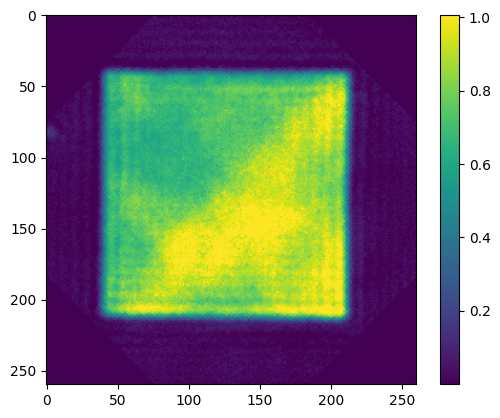

In [130]:
plot_od(rotate_image(img, -np.pi/4))

In [131]:
ods_centered = [rotate_image(shot.od[ctr_y-130:ctr_y+130,ctr_x-130:ctr_x+130], np.pi/4) for shot in shots]
od_mean = np.average(ods_centered, axis=0)

xs = np.arange(ods_centered[0].shape[1])*0.66e-6
ys = np.arange(ods_centered[0].shape[0])*0.66e-6

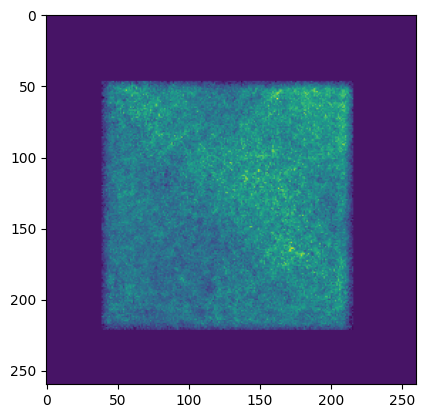

In [132]:
box_x = np.abs(np.sum(od_mean, axis=0)) > 20
box_y = np.abs(np.sum(od_mean, axis=1)) > 20

box_l = min(xs[box_x])
box_r = max(xs[box_x])

box_xs_len = box_r - box_l

box_xs_mask = (xs > box_l) & (xs < box_r)
box_xs = xs[box_xs_mask]
box_xs_offset = box_xs - box_l

box_u = min(ys[box_y])
box_d = max(ys[box_y])

box_ys_len = box_d - box_u

box_ys_mask = (ys > box_u) & (ys < box_d)
box_ys = ys[box_ys_mask]
box_ys_offset = box_ys - box_u

kx_unit = np.pi/box_xs_len
ky_unit = np.pi/box_ys_len

# print(box_xs_mask.shape, box_ys_mask.shape)
mask_data = np.outer(box_ys_mask, box_xs_mask)
plt.imshow(ods_centered[-1]*mask_data)
plt.show()

## coarsening data
- shot 6: 0ms
- shot 7: 800ms
- shot 9-12: 20,30,40,50ms
- shot 14: linspace(32e-3,38e-3,4)
- shot 15: linspace(60e-3,100e-3,5)
- shot 16: 25ms
- shot 18: linspace(150e-3,300e-3,4)
- shot 19: linspace(400e-3,700e-3,4)
- shot 20: linspace(1000e-3,2000e-3,4)
- shot 21: 45ms

In [159]:
shots_rec = simple_select_shots(2026, 8, 19, "bec_box2", [6,7,9,10,11,12,14,15,16,18,19,20,21])

shots = [ShotFile(s.shot_path, "cam6") for s in tqdm(shots_rec) if os.path.isfile(s.shot_path)]

shots[0].BOX_OPACITY

Total shots:  735


100%|██████████| 735/735 [00:09<00:00, 75.02it/s]


np.int32(1)

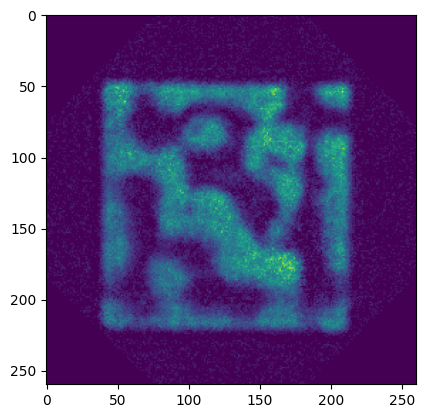

In [160]:
ods_centered = []

for shot in shots: #shots[:5]:
    img = rotate_image(shot.od[ctr_y-130:ctr_y+130,ctr_x-130:ctr_x+130], np.pi/4)
    bg = img*(~mask_data); threshold = np.mean(bg[bg>0]) #threshold2 = np.mean(bg);
    # print(threshold, threshold2)

    img[img<threshold]=0

    ods_centered.append(img)

# print(np.min(ods_centered))yy
# xs = np.arange(ods_centered[0].shape[1])*0.66e-6
# ys = np.arange(ods_centered[0].shape[0])*0.66e-6

import pandas as pd

df = pd.DataFrame({
    "t": [s.BEC_TIME_SEQ[6] for s in shots],
    "od_raw": [od for od in ods_centered],
    "od_mask": [od*mask_data for od in ods_centered]
})

plt.imshow(df["od_raw"][140])
# plt.imshow(df["od_raw"][140]*(~mask_data))
plt.show()

# for i in range(10):
#     img = df["od_mask"][i]
#     if np.min(img)<-0.1:
#         print(i)
#         plt.imshow(img)
#         plt.show()
#         plt.imshow(img<0)
#         plt.show()

In [161]:
times = np.unique(df["t"])
print("evolve times: ", times)

L_mean_svd1 = []
L_sem_svd1 = []

for ts_ in times:
    select = (df["t"]==ts_)
    img_s = df["od_mask"][select]
    X = np.stack([img_ for img_ in img_s])
    # print(X.shape)

    # evr_svd, pcs_svd = pca_svd(stack_svd)
    _, pcs_svd = pca_svd(X)
    Lt_svd1 = np.array([_domain_length_raw(remove_pca_components(img_,pcs_svd,1)[0])
                        for img_ in X])*0.66
    # print(len(Lt_svd1))
    L_mean_svd1.append(Lt_svd1.mean())
    L_sem_svd1.append(Lt_svd1.std(ddof=1)/np.sqrt(len(Lt_svd1)))

L_mean_svd1 = np.array(L_mean_svd1); L_sem_svd1 = np.array(L_sem_svd1)

evolve times:  [0.         0.02       0.025      0.03       0.032      0.034
 0.036      0.038      0.04       0.045      0.05       0.06
 0.07       0.08       0.09       0.1        0.15       0.2
 0.25       0.3        0.4        0.5        0.6        0.7
 0.8        1.         1.33333333 1.66666667 2.        ]


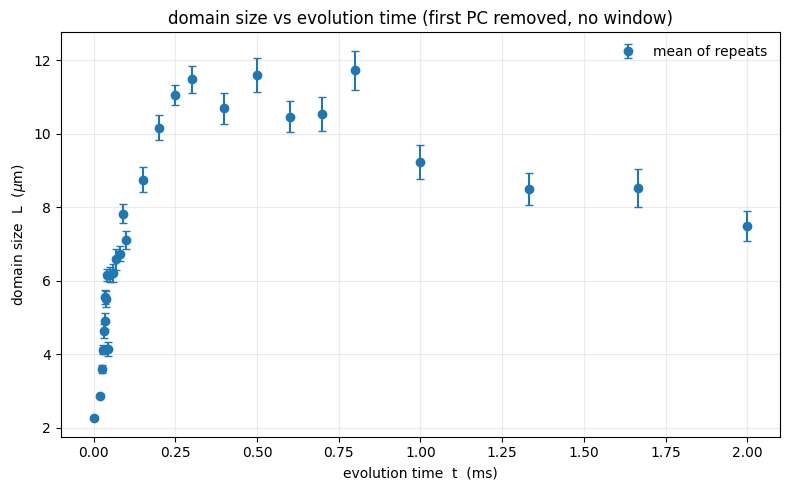

In [162]:
fig, ax = plt.subplots(figsize=(8, 5))
# ax.plot(t_shots_svd, L_shots_svd1, "o", ms=3, color="C0", alpha=0.3,
#         label="individual shots")
ax.errorbar(times, L_mean_svd1, yerr=L_sem_svd1, fmt="o", ms=6, color="C0",
            capsize=3, label="mean of repeats", zorder=3)
ax.set_xlabel("evolution time  t  (ms)")
ax.set_ylabel(r"domain size  L  ($\mu$m)")
ax.set_title("domain size vs evolution time (first PC removed, no window)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
# plt.xlim([0,60e-3])
plt.show()